<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

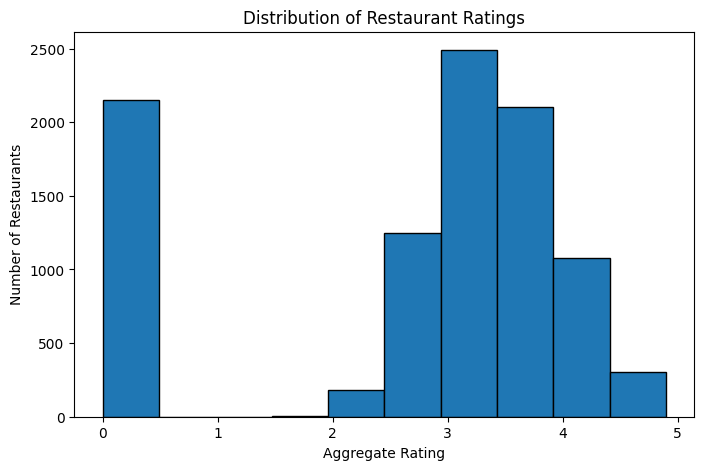

Most Common Rating: 0.0
Most Common Rating Range: 3-4
Average Votes: 156.91


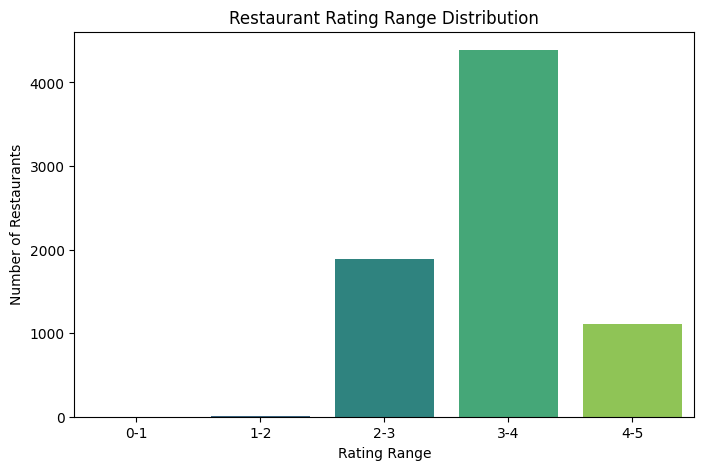

In [4]:
#Task1
#Import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#Load the Dataset
df = pd.read_csv("Dataset.csv")

#Display first 5 rows
df.head()

#Check Dataset Information
df.info()

#View Rating Column
df["Aggregate rating"].head(10)

#Decribe the Rating Column
df["Aggregate rating"].describe()

#Plot Rating Distribution
plt.figure(figsize=(8,5))
plt.hist(
    df["Aggregate rating"],
    bins=10,
    edgecolor="black")
plt.title("Distribution of Restaurant Ratings")
plt.xlabel("Aggregate Rating")
plt.ylabel("Number of Restaurants")
plt.show()

#Count Ratings
rating_count = df["Aggregate rating"].value_counts().sort_index()
rating_count

#Find the Most Common Rating
most_common_rating = rating_count.idxmax()
print("Most Common Rating:", most_common_rating)

#Create Rating Ranges
rating_ranges = pd.cut(
    df["Aggregate rating"],
    bins=[0,1,2,3,4,5],
    labels=[
        "0-1",
        "1-2",
        "2-3",
        "3-4",
        "4-5"    ])
rating_ranges

#Count Rating Ranges
range_count = rating_ranges.value_counts().sort_index()
range_count

#Find the Most Common Rating Range
most_common_range = range_count.idxmax()
print("Most Common Rating Range:", most_common_range)

#Calculate Average Votes
average_votes = df["Votes"].mean()
print("Average Votes:", round(average_votes, 2))

#Result Table
result = pd.DataFrame({
    "Rating Range": range_count.index,
    "Restaurant Count": range_count.values})
result

#Bar Chart
plt.figure(figsize=(8,5))
sns.barplot(
    x=range_count.index,
    y=range_count.values,
    hue=range_count.index,
    palette="viridis",
    legend=False
)
plt.title("Restaurant Rating Range Distribution")
plt.xlabel("Rating Range")
plt.ylabel("Number of Restaurants")
plt.show()




Cuisines
North Indian                      936
North Indian, Chinese             511
Chinese                           354
Fast Food                         354
North Indian, Mughlai             334
Cafe                              299
Bakery                            218
North Indian, Mughlai, Chinese    197
Bakery, Desserts                  170
Street Food                       149
Name: count, dtype: int64


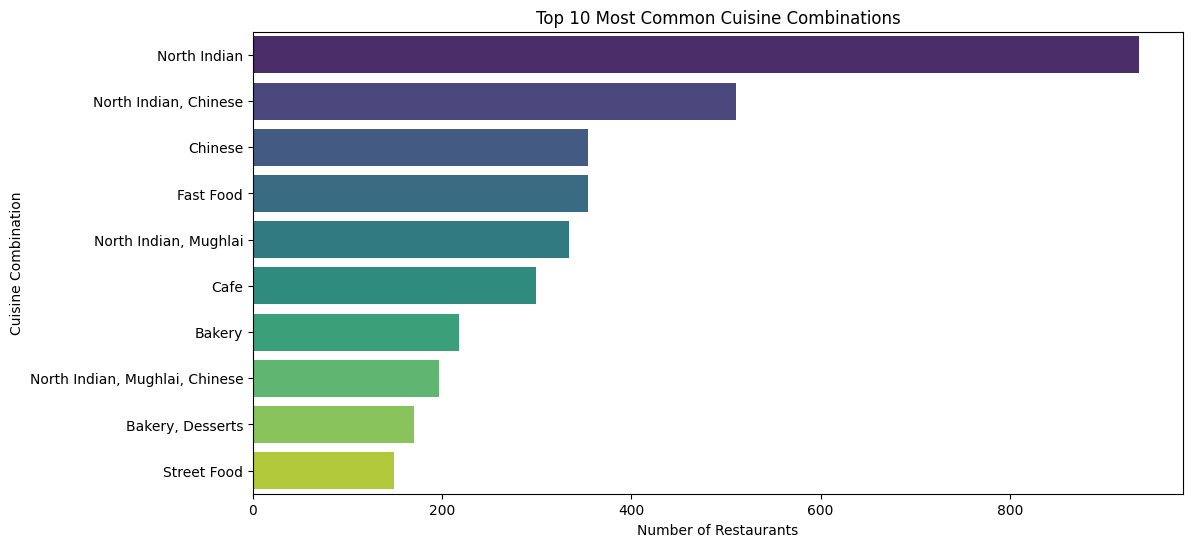

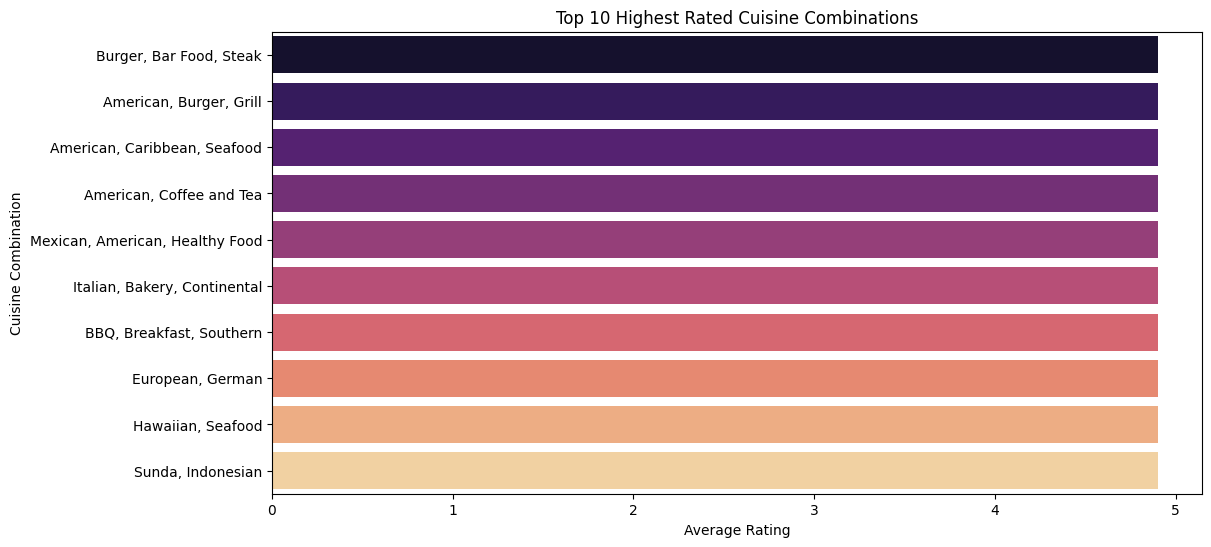

In [5]:
#Task2: Cuisine Combination

#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#Load Dataset
df=pd.read_csv("Dataset.csv")

#Display First 5 Rows
df.head()

#Check Missing Values
df["Cuisines"].isnull().sum()

#Remove Missing Values
df_cuisine = df.dropna(subset=["Cuisines"])

#View Cuisine Combinations
df_cuisine["Cuisines"].head(10)

#Count Cuisine Combinations
cuisine_count = df_cuisine["Cuisines"].value_counts()
cuisine_count.head(10)

#Top 10 Cuisine Combinations
top_10=cuisine_count.head(10)
print(top_10)

#Calculate Average Rating for Each Cuisine Combination
average_rating=df_cuisine.groupby("Cuisines")["Aggregate rating"].mean()


#Round Ratings
average_rating = average_rating.round(2)
average_rating.head(10)

#Highest Rated Cuisine Combinations
highest_rating = average_rating.sort_values(ascending=False)
highest_rating.head(10)

#Result table
result = pd.DataFrame({
    "Average Rating": highest_rating.head(10)})
result

#Bar Chart (Most Common Cuisine Combinations)
plt.figure(figsize=(12,6))
sns.barplot(
    x=top_10.values,
    y=top_10.index,
    hue=top_10.index,
    palette="viridis",
    legend=False)
plt.title("Top 10 Most Common Cuisine Combinations")
plt.xlabel("Number of Restaurants")
plt.ylabel("Cuisine Combination")
plt.show()

#Bar Chart(Highest Rated Cuisine Combinations)
plt.figure(figsize=(12,6))
sns.barplot(
    x=highest_rating.head(10).values,
    y=highest_rating.head(10).index,
    hue=highest_rating.head(10).index,
    palette="magma",
    legend=False)
plt.title("Top 10 Highest Rated Cuisine Combinations")
plt.xlabel("Average Rating")
plt.ylabel("Cuisine Combination")
plt.show()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

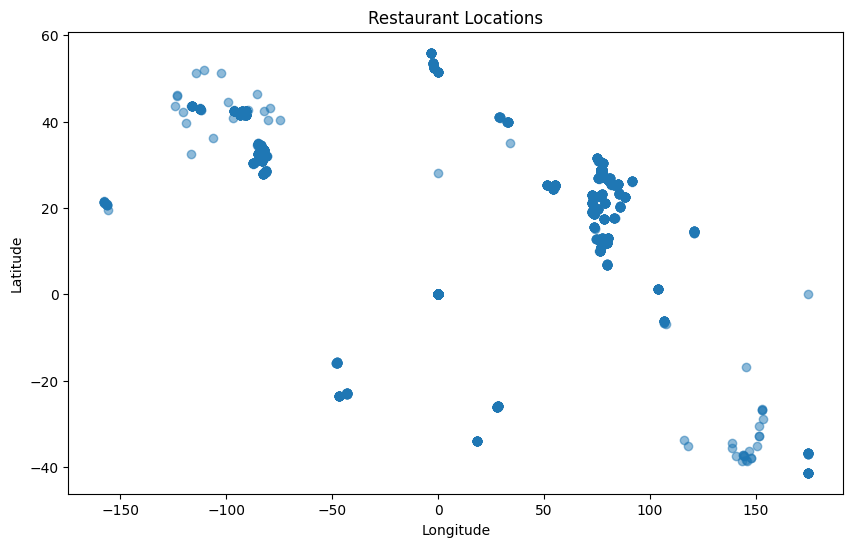

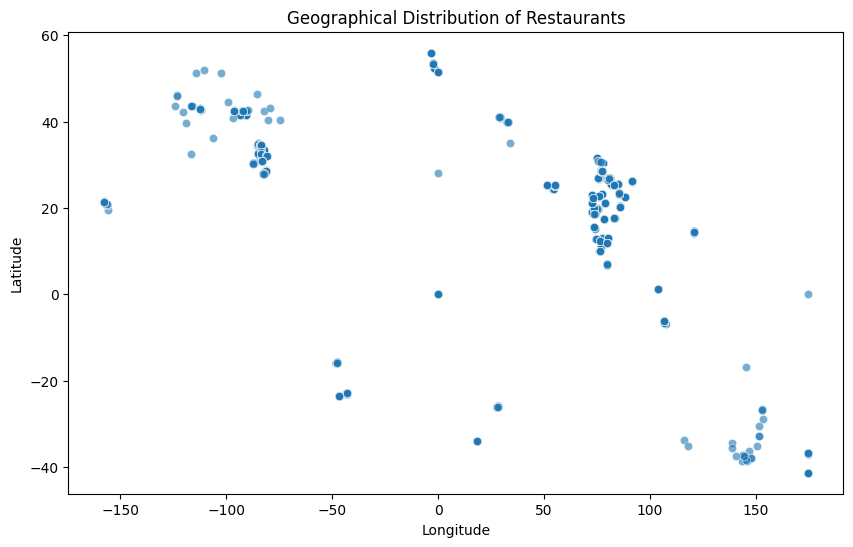

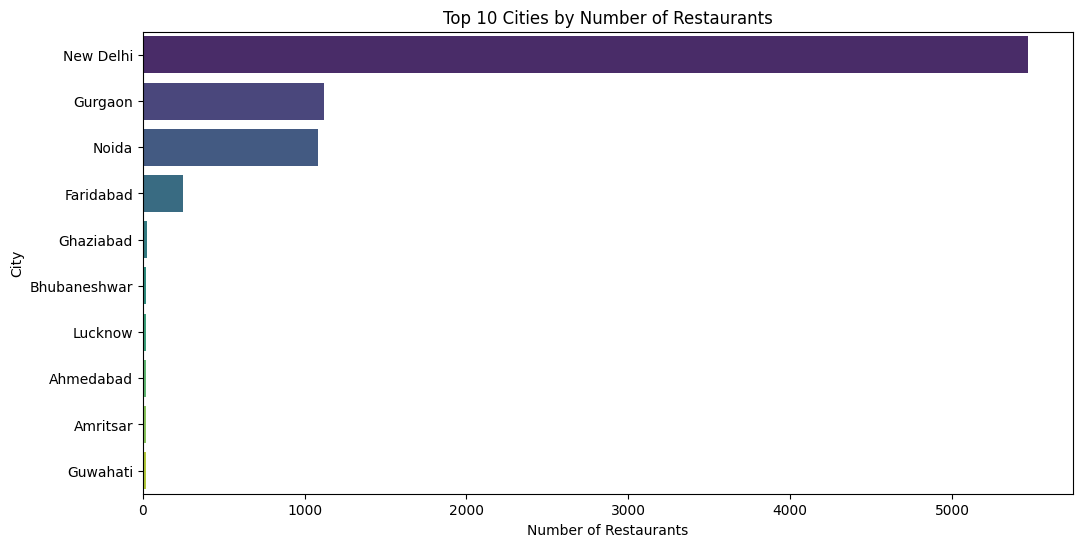

,City,Latitude,Longitude
0,Abu Dhabi,24.464269,54.405998
1,Agra,19.016683,54.622830
2,Ahmedabad,23.036910,72.531324
3,Albany,31.602963,-84.186592
4,Allahabad,19.089371,61.378793
...,...,...,...
136,Weirton,40.396043,-80.529488
137,Wellington City,-41.293814,174.778100
138,Winchester Bay,43.678998,-124.175346
139,Yorkton,51.210682,-102.461317


In [6]:
#task3
#import libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#Load Dataset
df=pd.read_csv("Dataset.csv")

#Display First Five Rows
df.head()

#Dataset Information
df.info()

#Check Missing Value
df[["Latitude", "Longitude"]].isnull().sum()

#View Latitude and Longitude
df[["Restaurant Name", "City", "Latitude", "Longitude"]].head(10)

#Scatter Plot of Restaurant Locations
plt.figure(figsize=(10,6))
plt.scatter(
    df["Longitude"],
    df["Latitude"],
    alpha=0.5)
plt.title("Restaurant Locations")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

#Scatter Plot with Seaborn
plt.figure(figsize=(10,6))
sns.scatterplot(
    x="Longitude",
    y="Latitude",
    data=df,
    alpha=0.6)
plt.title("Geographical Distribution of Restaurants")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

#Restaurant Count by City
city_count = df["City"].value_counts()
city_count.head(10)

# Bar chart
plt.figure(figsize=(12,6))
sns.barplot(
    x=city_count.head(10).values,
    y=city_count.head(10).index,
    hue=city_count.head(10).index,
    palette="viridis",
    legend=False)
plt.title("Top 10 Cities by Number of Restaurants")
plt.xlabel("Number of Restaurants")
plt.ylabel("City")
plt.show()

#Average Location of Restaurants by city
city_location = df.groupby("City")[["Latitude", "Longitude"]].mean()
city_location.head()

#Display Result
city_location.reset_index()




<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9551 entries, 0 to 9550
Data columns (total 21 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   Restaurant ID         9551 non-null   int64  
 1   Restaurant Name       9551 non-null   object 
 2   Country Code          9551 non-null   int64  
 3   City                  9551 non-null   object 
 4   Address               9551 non-null   object 
 5   Locality              9551 non-null   object 
 6   Locality Verbose      9551 non-null   object 
 7   Longitude             9551 non-null   float64
 8   Latitude              9551 non-null   float64
 9   Cuisines              9542 non-null   object 
 10  Average Cost for two  9551 non-null   int64  
 11  Currency              9551 non-null   object 
 12  Has Table booking     9551 non-null   object 
 13  Has Online delivery   9551 non-null   object 
 14  Is delivering now     9551 non-null   object 
 15  Switch to order menu 

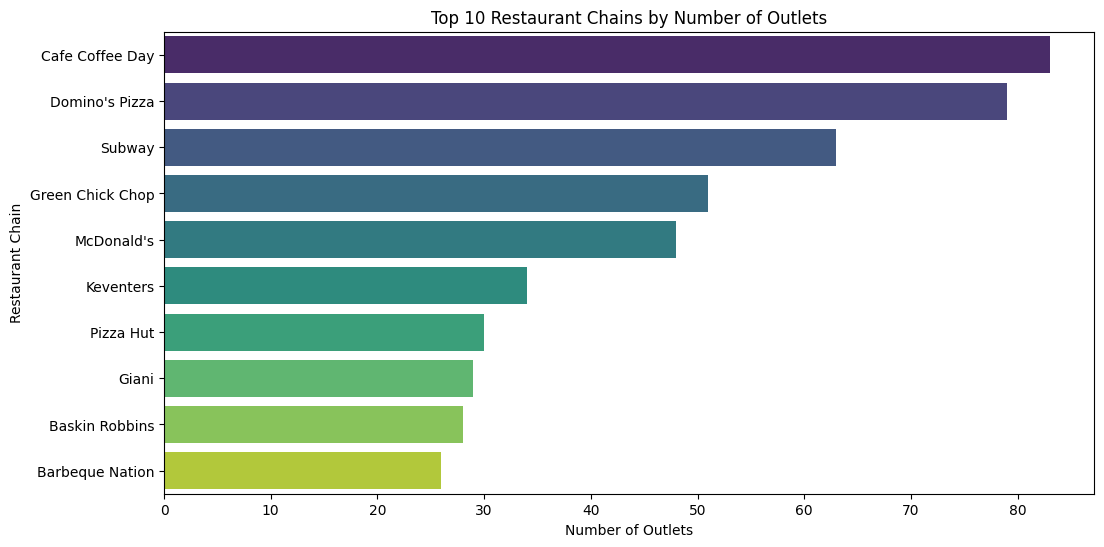

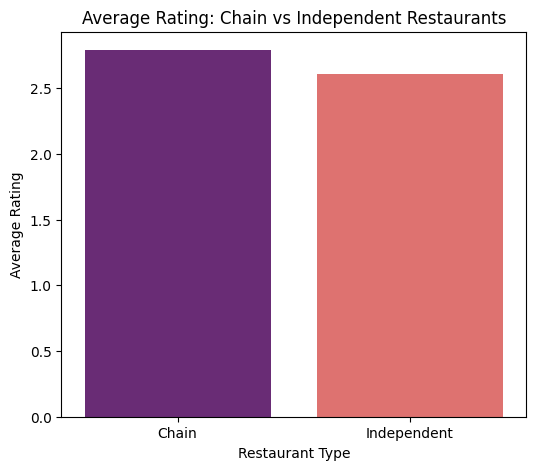

In [7]:
#Task4:Restaurant Chains
#import Libraries
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
%matplotlib inline

#Load Dataset
df=pd.read_csv("Dataset.csv")

#Display First Five Rows
df.head()

#Dataset Information
df.info()

#Check Missing Values in Restaurant Name
df["Restaurant Name"].isnull().sum()

#Count Restaurant Names
restaurant_count = df["Restaurant Name"].value_counts()
restaurant_count.head(10)

#Display Restaurant Chains
restaurant_chains = restaurant_count[restaurant_count > 1]
restaurant_chains.head(10)

#Top 10 Restaurant Chains
top_chains = restaurant_chains.head(10)
top_chains

#Result Table
chain_table = top_chains.reset_index()
chain_table.columns = [
    "Restaurant Chain",
    "Number of Outlets"]
chain_table

#Calculate Average Rating
chain_rating = df.groupby("Restaurant Name")["Aggregate rating"].mean().round(2)
chain_rating.head()

#Combine Outlet Count and Average Rating
chain_summary = pd.DataFrame({
    "Number of Outlets": restaurant_count,
    "Average Rating": chain_rating})
chain_summary.head()

#Keep Only Restaurant Chains
chain_summary = chain_summary[
    chain_summary["Number of Outlets"] > 1]
chain_summary.head()

#Highest Rated Restaurant Chains
highest_rated = chain_summary.sort_values(
    by="Average Rating",
    ascending=False)
highest_rated.head(10)

#Create Chain Indicator
df["Restaurant Type"] = np.where(
    df["Restaurant Name"].isin(restaurant_chains.index),
    "Chain",
    "Independent")
df.head()

#Average Rating Comparison
rating_comparison = df.groupby("Restaurant Type")["Aggregate rating"].mean().round(2)
rating_comparison

#Result Table
comparison_table = rating_comparison.reset_index()
comparison_table.columns = [
    "Restaurant Type",
    "Average Rating"]
comparison_table

#Top Restaurant Chains
plt.figure(figsize=(12,6))
sns.barplot(
    x=top_chains.values,
    y=top_chains.index,
    hue=top_chains.index,
    palette="viridis",
    legend=False)
plt.title("Top 10 Restaurant Chains by Number of Outlets")
plt.xlabel("Number of Outlets")
plt.ylabel("Restaurant Chain")
plt.show()

#Chain vs Independent Ratings
plt.figure(figsize=(6,5))
sns.barplot(
    x=rating_comparison.index,
    y=rating_comparison.values,
    hue=rating_comparison.index,
    palette="magma",
    legend=False)
plt.title("Average Rating: Chain vs Independent Restaurants")
plt.xlabel("Restaurant Type")
plt.ylabel("Average Rating")
plt.show()



